# **Week 13 Unpredictability and Abstention**

AGAINST ALL ODDS — WEEK 13A: UNPREDICTABILITY INDEX

Upload these missing Week 13 files:
 - week12_all_sports_error_risk_test_predictions.csv
 - week10_nba_calibrated_test_predictions.csv
 - week10_nfl_calibrated_test_predictions.csv
 - week10_premier_league_calibrated_test_predictions.csv


Saving unpredictability index.zip to unpredictability index.zip

Inputs located:
 - week12_all_sports_error_risk_test_predictions.csv -> /content/week13_inputs/week12_all_sports_error_risk_test_predictions.csv
 - week10_nba_calibrated_test_predictions.csv -> /content/week13_inputs/week10_nba_calibrated_test_predictions.csv
 - week10_nfl_calibrated_test_predictions.csv -> /content/week13_inputs/week10_nfl_calibrated_test_predictions.csv
 - week10_premier_league_calibrated_test_predictions.csv -> /content/week13_inputs/week10_premier_league_calibrated_test_predictions.csv

Unpredictability summary by sport:


,sport,games,mean_unpredictability_index,median_unpredictability_index,mean_fragility_score,mean_error_risk_probability,actual_prediction_accuracy
0,NBA,1209,47.249446,47.850,63.564930,0.491616,0.689826
1,NFL,255,48.198471,46.410,62.230392,0.478542,0.639216
2,Premier League,370,48.278568,48.235,60.760135,0.494527,0.624324



Predict / Caution / Abstain summary:


,sport,RELIABILITY_CATEGORY,games,mean_unpredictability_index,prediction_accuracy,actual_error_rate,mean_error_risk_probability,mean_fragility_score
0,NBA,Abstain,179,74.975978,0.586592,0.413408,0.630490,89.036313
1,NBA,Caution,760,49.130171,0.663158,0.336842,0.528015,70.074013
2,NBA,Predict,270,23.573889,0.833333,0.166667,0.297090,28.356481
3,NFL,Abstain,42,79.089048,0.619048,0.380952,0.625133,87.648810
4,NFL,Caution,152,49.090987,0.625000,0.375000,0.498294,68.626645
5,NFL,Predict,61,24.705574,0.688525,0.311475,0.328394,28.790984
6,Premier League,Abstain,60,75.351000,0.533333,0.466667,0.604752,89.062500
7,Premier League,Caution,225,50.680178,0.573333,0.426667,0.537881,67.277778
8,Premier League,Predict,85,22.811412,0.823529,0.176471,0.301958,23.529412


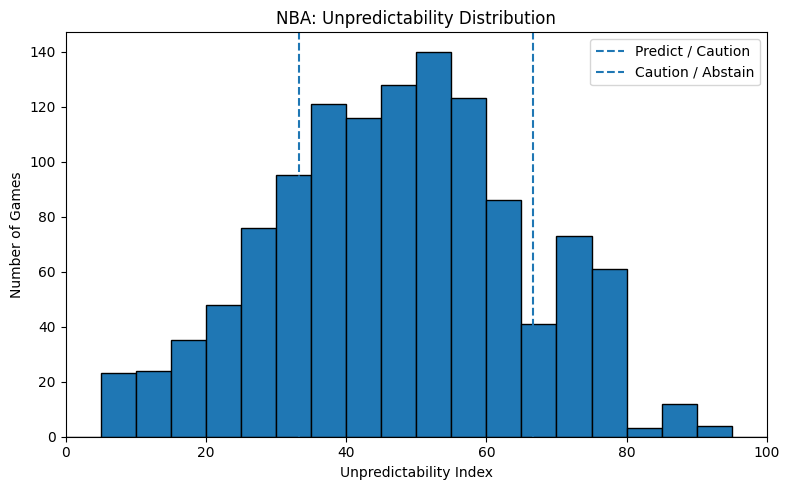

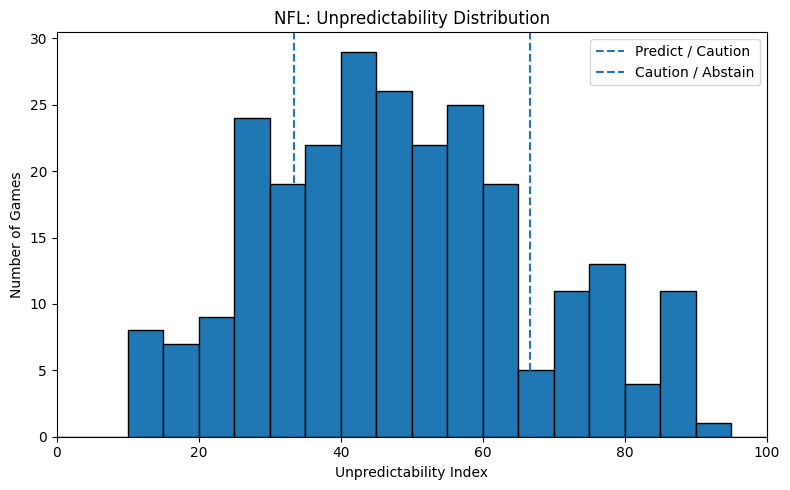

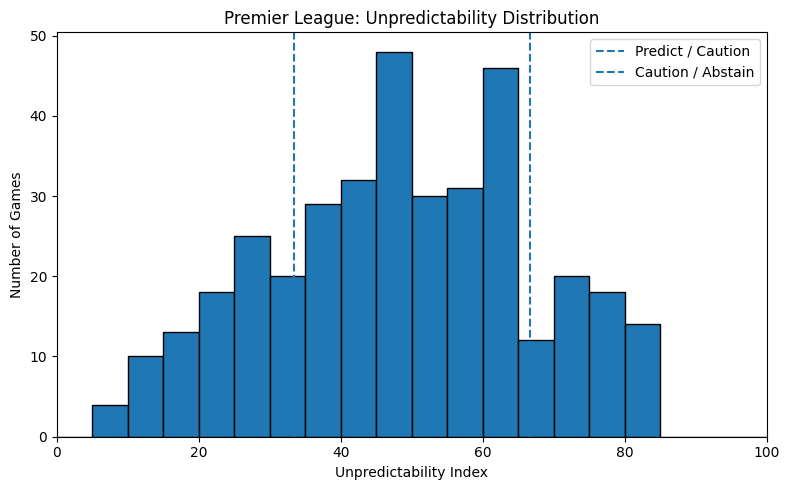

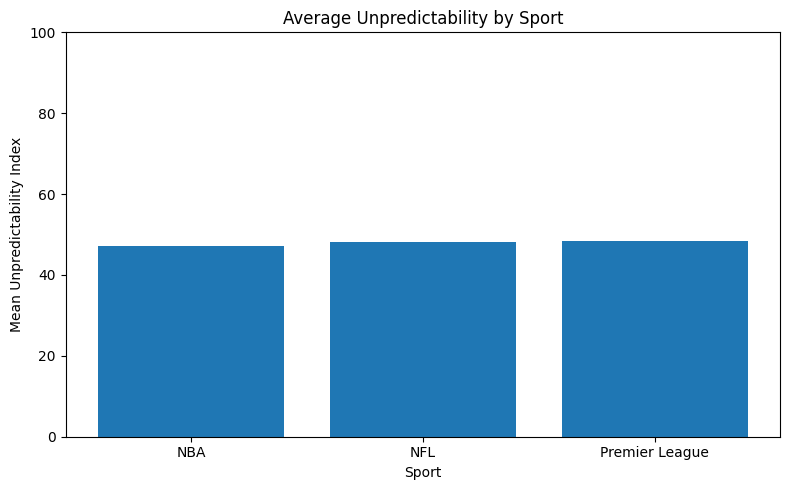

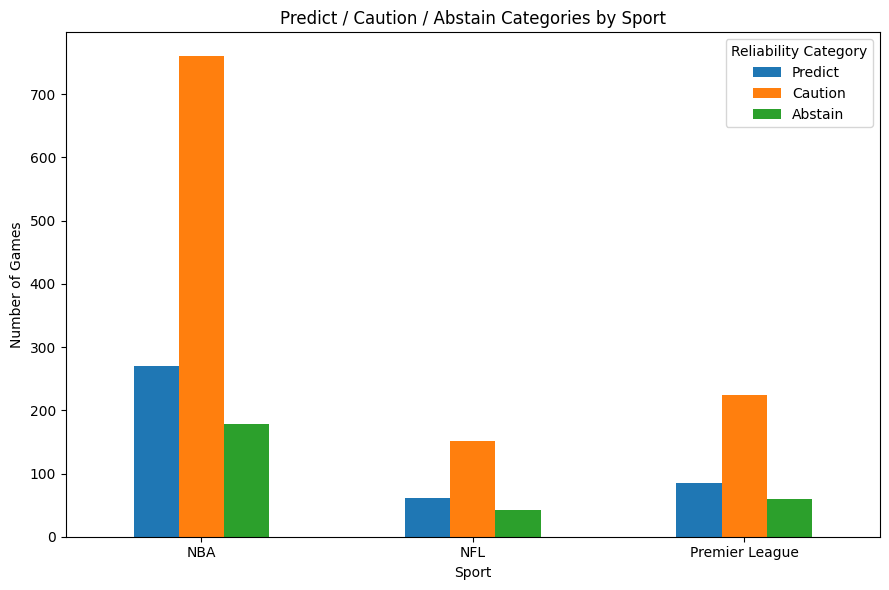


Week 13A quality checks:


,check,passed
0,three_sports_present,True
1,index_between_0_and_100,True
2,calibrated_probability_valid,True
3,fragility_valid,True
4,error_risk_valid,True
5,disagreement_valid,True
6,categories_valid,True



✅ Week 13A complete. Run 16_abstention_analysis.ipynb next.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json, sys, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(x): print(x)

warnings.filterwarnings('ignore', category=FutureWarning)
PROJECT_TITLE = 'Against All Odds'
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

WEEK12_INPUT = 'week12_all_sports_error_risk_test_predictions.csv'
WEEK10_INPUTS = {
    'NBA': 'week10_nba_calibrated_test_predictions.csv',
    'NFL': 'week10_nfl_calibrated_test_predictions.csv',
    'Premier League': 'week10_premier_league_calibrated_test_predictions.csv',
}
WEIGHTS = {
    'CALIBRATED_UNCERTAINTY_COMPONENT': 0.25,
    'FRAGILITY_COMPONENT': 0.25,
    'ERROR_RISK_COMPONENT': 0.25,
    'MODEL_DISAGREEMENT_COMPONENT': 0.25,
}
PREDICT_MAX = 100/3
CAUTION_MAX = 200/3

print('=' * 78)
print('AGAINST ALL ODDS — WEEK 13A: UNPREDICTABILITY INDEX')
print('=' * 78)


def running_in_colab():
    return 'google.colab' in sys.modules


def choose_project_root():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd if cwd.name.lower().replace('_','-') in {'againstallodds','against-all-odds'} else None,
        Path('/content/againstallodds'),
        Path('/content/Against-All-Odds'),
        Path('/content/drive/MyDrive/againstallodds'),
        Path('/content/drive/MyDrive/Against-All-Odds'),
    ]
    for c in candidates:
        if c is not None and c.exists(): return c
    return Path('/content/againstallodds') if running_in_colab() else cwd/'againstallodds'


PROJECT_ROOT = choose_project_root()
RESULTS_DIR = PROJECT_ROOT/'results'
FIGURES_DIR = PROJECT_ROOT/'figures'/'week13'
DOCS_DIR = PROJECT_ROOT/'docs'
for p in [RESULTS_DIR, FIGURES_DIR, DOCS_DIR]: p.mkdir(parents=True, exist_ok=True)


def search_locations():
    locs = [PROJECT_ROOT, RESULTS_DIR, Path('/content'), Path('/content/week13_inputs'), Path.cwd().resolve()]
    for extra in [Path('/content/drive/MyDrive/againstallodds'), Path('/content/drive/MyDrive/Against-All-Odds')]:
        if extra.exists(): locs.append(extra)
    return list(dict.fromkeys(p for p in locs if p.exists()))


def find_file(name):
    for root in search_locations():
        p = root/name
        if p.exists(): return p
    for root in search_locations():
        try: hits = list(root.rglob(name))
        except (PermissionError, OSError): hits = []
        if hits: return hits[0]
    return None


def locate_inputs():
    required = [WEEK12_INPUT] + list(WEEK10_INPUTS.values())
    found = {name: find_file(name) for name in required}
    missing = [n for n,p in found.items() if p is None]
    if missing and running_in_colab():
        print('\nUpload these missing Week 13 files:')
        for n in missing: print(' -', n)
        from google.colab import files
        uploaded = files.upload()
        udir = Path('/content/week13_inputs'); udir.mkdir(parents=True, exist_ok=True)
        for name, blob in uploaded.items():
            dst = udir/Path(name).name; dst.write_bytes(blob)
            if zipfile.is_zipfile(dst):
                with zipfile.ZipFile(dst,'r') as z: z.extractall(udir)
        found = {name: find_file(name) for name in required}
    missing = [n for n,p in found.items() if p is None]
    if missing:
        raise FileNotFoundError('Missing Week 13 inputs:\n' + '\n'.join(' - '+n for n in missing) + '\nRun Weeks 10 and 12 first or upload these files.')
    return found


FILES = locate_inputs()
print('\nInputs located:')
for n,p in FILES.items(): print(' -', n, '->', p)

# Week 12 error-risk output
w12 = pd.read_csv(FILES[WEEK12_INPUT], dtype={'game_id':'string'})
required12 = ['sport','game_id','HOME_WIN','PRIMARY_MODEL','ORIGINAL_PREDICTION','PRIMARY_MODEL_CORRECT','PRIMARY_MODEL_ERROR','FRAGILITY_SCORE','ERROR_RISK_PROBABILITY','MODEL_DISAGREEMENT_COUNT']
missing = [c for c in required12 if c not in w12.columns]
if missing: raise ValueError(f'Week 12 input missing columns: {missing}')
w12['sport'] = w12['sport'].astype('string').str.strip()
w12['game_id'] = w12['game_id'].astype('string')
for c in ['HOME_WIN','ORIGINAL_PREDICTION','PRIMARY_MODEL_CORRECT','PRIMARY_MODEL_ERROR','FRAGILITY_SCORE','ERROR_RISK_PROBABILITY','MODEL_DISAGREEMENT_COUNT']:
    w12[c] = pd.to_numeric(w12[c], errors='coerce')
if w12[['sport','game_id']].duplicated().any(): raise ValueError('Duplicate sport/game_id rows in Week 12 input.')

# Week 10 calibrated probabilities
cal_frames = []
for sport, filename in WEEK10_INPUTS.items():
    x = pd.read_csv(FILES[filename], dtype={'game_id':'string'})
    req = ['game_id','HOME_WIN','CALIBRATED_HOME_WIN_PROB']
    miss = [c for c in req if c not in x.columns]
    if miss: raise ValueError(f'{sport} Week 10 file missing columns: {miss}')
    x['game_id'] = x['game_id'].astype('string')
    x['HOME_WIN'] = pd.to_numeric(x['HOME_WIN'], errors='coerce')
    x['CALIBRATED_HOME_WIN_PROB'] = pd.to_numeric(x['CALIBRATED_HOME_WIN_PROB'], errors='coerce')
    x['sport'] = sport
    if x['game_id'].duplicated().any(): raise ValueError(f'{sport} Week 10 file has duplicate game_id rows.')
    cal_frames.append(x[['sport','game_id','HOME_WIN','CALIBRATED_HOME_WIN_PROB']])
cal = pd.concat(cal_frames, ignore_index=True)
if not cal['CALIBRATED_HOME_WIN_PROB'].between(0,1).all(): raise ValueError('Calibrated probabilities must be between 0 and 1.')

# Merge reliability signals
m = w12.merge(cal, on=['sport','game_id'], how='left', suffixes=('','_WEEK10'), validate='one_to_one')
if m['CALIBRATED_HOME_WIN_PROB'].isna().any():
    raise ValueError('Some Week 12 TEST games could not be matched to Week 10 calibrated probabilities.')
if 'HOME_WIN_WEEK10' in m.columns:
    bad = m['HOME_WIN_WEEK10'].notna() & (m['HOME_WIN'].astype(float) != m['HOME_WIN_WEEK10'].astype(float))
    if bad.any(): raise ValueError('Week 10 and Week 12 outcomes do not match.')

# Components, all on a 0–100 uncertainty scale
p = m['CALIBRATED_HOME_WIN_PROB']
m['CALIBRATED_CONFIDENCE'] = np.maximum(p, 1-p)
m['CALIBRATED_UNCERTAINTY_COMPONENT'] = (100*(1-(np.abs(p-0.5)/0.5))).clip(0,100)
m['FRAGILITY_COMPONENT'] = m['FRAGILITY_SCORE'].clip(0,100)
m['ERROR_RISK_COMPONENT'] = (100*m['ERROR_RISK_PROBABILITY'].clip(0,1))
m['MODEL_DISAGREEMENT_COMPONENT'] = (100*(m['MODEL_DISAGREEMENT_COUNT'].clip(0,2)/2.0))

m['UNPREDICTABILITY_INDEX'] = 0.0
for comp, wt in WEIGHTS.items(): m['UNPREDICTABILITY_INDEX'] += m[comp]*wt
m['UNPREDICTABILITY_INDEX'] = m['UNPREDICTABILITY_INDEX'].clip(0,100).round(2)


def category(score):
    if score < PREDICT_MAX: return 'Predict'
    if score < CAUTION_MAX: return 'Caution'
    return 'Abstain'

m['RELIABILITY_CATEGORY'] = m['UNPREDICTABILITY_INDEX'].map(category)
m['RELIABILITY_INTERPRETATION'] = m['RELIABILITY_CATEGORY'].map({'Predict':'Low uncertainty','Caution':'Moderate uncertainty','Abstain':'Very high uncertainty'})
m['WINNER_PREDICTION'] = m['ORIGINAL_PREDICTION'].astype(int)
m['WINNER_PREDICTION_CORRECT'] = m['PRIMARY_MODEL_CORRECT'].astype(int)

INDEX_PATH = RESULTS_DIR/'week13_unpredictability_index.csv'
m.to_csv(INDEX_PATH, index=False)

sport_summary = m.groupby('sport').agg(
    games=('game_id','size'),
    mean_unpredictability_index=('UNPREDICTABILITY_INDEX','mean'),
    median_unpredictability_index=('UNPREDICTABILITY_INDEX','median'),
    mean_fragility_score=('FRAGILITY_SCORE','mean'),
    mean_error_risk_probability=('ERROR_RISK_PROBABILITY','mean'),
    actual_prediction_accuracy=('WINNER_PREDICTION_CORRECT','mean'),
).reset_index()

category_summary = m.groupby(['sport','RELIABILITY_CATEGORY'], observed=False).agg(
    games=('game_id','size'),
    mean_unpredictability_index=('UNPREDICTABILITY_INDEX','mean'),
    prediction_accuracy=('WINNER_PREDICTION_CORRECT','mean'),
    actual_error_rate=('PRIMARY_MODEL_ERROR','mean'),
    mean_error_risk_probability=('ERROR_RISK_PROBABILITY','mean'),
    mean_fragility_score=('FRAGILITY_SCORE','mean'),
).reset_index()

component_summary = m.groupby('sport')[list(WEIGHTS.keys())].mean().reset_index()
SPORT_SUMMARY_PATH = RESULTS_DIR/'week13_unpredictability_summary_by_sport.csv'
CATEGORY_SUMMARY_PATH = RESULTS_DIR/'week13_reliability_category_summary.csv'
COMPONENT_SUMMARY_PATH = RESULTS_DIR/'week13_unpredictability_component_summary.csv'
sport_summary.to_csv(SPORT_SUMMARY_PATH,index=False)
category_summary.to_csv(CATEGORY_SUMMARY_PATH,index=False)
component_summary.to_csv(COMPONENT_SUMMARY_PATH,index=False)

print('\nUnpredictability summary by sport:')
display(sport_summary)
print('\nPredict / Caution / Abstain summary:')
display(category_summary)

# Figures
for sport in ['NBA','NFL','Premier League']:
    s = m[m['sport'].eq(sport)]
    fig, ax = plt.subplots(figsize=(8,5))
    ax.hist(s['UNPREDICTABILITY_INDEX'], bins=np.arange(0,105,5), edgecolor='black')
    ax.axvline(PREDICT_MAX, linestyle='--', label='Predict / Caution')
    ax.axvline(CAUTION_MAX, linestyle='--', label='Caution / Abstain')
    ax.set(xlim=(0,100), xlabel='Unpredictability Index', ylabel='Number of Games', title=f'{sport}: Unpredictability Distribution')
    ax.legend(); fig.tight_layout()
    safe = sport.lower().replace(' ','_')
    fig.savefig(FIGURES_DIR/f'week13_{safe}_unpredictability_distribution.png', dpi=160, bbox_inches='tight')
    plt.show(); plt.close(fig)

fig, ax = plt.subplots(figsize=(8,5))
ax.bar(sport_summary['sport'], sport_summary['mean_unpredictability_index'])
ax.set(ylim=(0,100), xlabel='Sport', ylabel='Mean Unpredictability Index', title='Average Unpredictability by Sport')
fig.tight_layout(); fig.savefig(FIGURES_DIR/'week13_mean_unpredictability_by_sport.png', dpi=160, bbox_inches='tight'); plt.show(); plt.close(fig)

cat_order = ['Predict','Caution','Abstain']
counts = m.groupby(['sport','RELIABILITY_CATEGORY'], observed=False).size().unstack(fill_value=0).reindex(columns=cat_order, fill_value=0)
fig, ax = plt.subplots(figsize=(9,6)); counts.plot(kind='bar', ax=ax)
ax.set(xlabel='Sport', ylabel='Number of Games', title='Predict / Caution / Abstain Categories by Sport')
ax.tick_params(axis='x', rotation=0); ax.legend(title='Reliability Category'); fig.tight_layout()
fig.savefig(FIGURES_DIR/'week13_reliability_categories_by_sport.png', dpi=160, bbox_inches='tight'); plt.show(); plt.close(fig)

methodology = {
    'project': PROJECT_TITLE,
    'week': 13,
    'index_name': 'Against All Odds Unpredictability Index',
    'range': '0 to 100; higher = more unpredictable',
    'formula_note': 'The capstone draft names the inputs but does not prescribe an exact formula. This implementation uses a transparent equal-weight composite.',
    'weights': WEIGHTS,
    'components': {
        'CALIBRATED_UNCERTAINTY_COMPONENT': '100 * (1 - abs(calibrated home-win probability - 0.50) / 0.50)',
        'FRAGILITY_COMPONENT': 'Week 11 Fragility Score',
        'ERROR_RISK_COMPONENT': '100 * Week 12 ERROR_RISK_PROBABILITY',
        'MODEL_DISAGREEMENT_COMPONENT': '100 * MODEL_DISAGREEMENT_COUNT / 2',
    },
    'categories': {
        'Predict': f'0 <= index < {PREDICT_MAX:.2f}',
        'Caution': f'{PREDICT_MAX:.2f} <= index < {CAUTION_MAX:.2f}',
        'Abstain': f'{CAUTION_MAX:.2f} <= index <= 100',
    },
    'evaluation_split': 'TEST',
}
METHODOLOGY_PATH = RESULTS_DIR/'week13_unpredictability_methodology.json'
METHODOLOGY_PATH.write_text(json.dumps(methodology, indent=2), encoding='utf-8')

summary_lines = [f"- {r.sport}: mean index {r.mean_unpredictability_index:.2f}; prediction accuracy {r.actual_prediction_accuracy:.1%}." for r in sport_summary.itertuples(index=False)]
doc = f'''# Against All Odds — Week 13A Unpredictability Index

Generated: {datetime.now(timezone.utc).isoformat(timespec='seconds')}

Week 13 combines winner prediction, calibrated probability, Fragility Score, error-risk probability, and model disagreement into the Against All Odds Unpredictability Index.

The capstone draft does not give an exact formula, so this implementation uses four equally weighted 0–100 uncertainty components: calibrated probability uncertainty, Fragility Score, error-risk probability, and model disagreement. Higher scores mean more uncertainty.

Categories:
- Predict: low uncertainty, below {PREDICT_MAX:.2f}
- Caution: moderate uncertainty, {PREDICT_MAX:.2f} to below {CAUTION_MAX:.2f}
- Abstain: very high uncertainty, at least {CAUTION_MAX:.2f}

TEST summary:
{chr(10).join(summary_lines)}

Notebook 16 uses this index for the required abstention experiment.
'''
DOC_PATH = DOCS_DIR/'week13_unpredictability_index.md'
DOC_PATH.write_text(doc, encoding='utf-8')

checks = {
    'three_sports_present': set(m['sport'].unique()) == {'NBA','NFL','Premier League'},
    'index_between_0_and_100': m['UNPREDICTABILITY_INDEX'].between(0,100).all(),
    'calibrated_probability_valid': m['CALIBRATED_HOME_WIN_PROB'].between(0,1).all(),
    'fragility_valid': m['FRAGILITY_SCORE'].between(0,100).all(),
    'error_risk_valid': m['ERROR_RISK_PROBABILITY'].between(0,1).all(),
    'disagreement_valid': m['MODEL_DISAGREEMENT_COUNT'].between(0,2).all(),
    'categories_valid': set(m['RELIABILITY_CATEGORY'].unique()).issubset({'Predict','Caution','Abstain'}),
}
q = pd.DataFrame([{'check':k,'passed':bool(v)} for k,v in checks.items()])
QUALITY_PATH = RESULTS_DIR/'week13_unpredictability_quality_report.csv'; q.to_csv(QUALITY_PATH,index=False)
print('\nWeek 13A quality checks:'); display(q)
if not q['passed'].all(): raise RuntimeError('Week 13A quality checks failed.')
print('\n✅ Week 13A complete. Run 16_abstention_analysis.ipynb next.')


AGAINST ALL ODDS — WEEK 13B: ABSTENTION ANALYSIS
Index input: /content/againstallodds/results/week13_unpredictability_index.csv

Required 100/90/80/70/60 coverage experiment:


,sport,requested_coverage_percent,games_predicted,games_abstained,prediction_accuracy,prediction_error_rate,accuracy_improvement_vs_100pct
0,NBA,100.0,1209,0,0.689826,0.310174,0.000000
1,NBA,90.0,1089,120,0.704316,0.295684,0.014490
2,NBA,80.0,968,241,0.721074,0.278926,0.031248
3,NBA,70.0,847,362,0.733176,0.266824,0.043350
4,NBA,60.0,726,483,0.752066,0.247934,0.062240
5,NFL,100.0,255,0,0.639216,0.360784,0.000000
6,NFL,90.0,230,25,0.643478,0.356522,0.004263
7,NFL,80.0,204,51,0.647059,0.352941,0.007843
8,NFL,70.0,179,76,0.659218,0.340782,0.020002
9,NFL,60.0,153,102,0.679739,0.320261,0.040523



Predict / Caution / Abstain performance:


,sport,RELIABILITY_CATEGORY,games,prediction_accuracy,mean_unpredictability_index,mean_error_risk_probability,mean_fragility_score,prediction_error_rate
0,NBA,Abstain,179,0.586592,74.975978,0.630490,89.036313,0.413408
1,NBA,Caution,760,0.663158,49.130171,0.528015,70.074013,0.336842
2,NBA,Predict,270,0.833333,23.573889,0.297090,28.356481,0.166667
3,NFL,Abstain,42,0.619048,79.089048,0.625133,87.648810,0.380952
4,NFL,Caution,152,0.625000,49.090987,0.498294,68.626645,0.375000
5,NFL,Predict,61,0.688525,24.705574,0.328394,28.790984,0.311475
6,Premier League,Abstain,60,0.533333,75.351000,0.604752,89.062500,0.466667
7,Premier League,Caution,225,0.573333,50.680178,0.537881,67.277778,0.426667
8,Premier League,Predict,85,0.823529,22.811412,0.301958,23.529412,0.176471


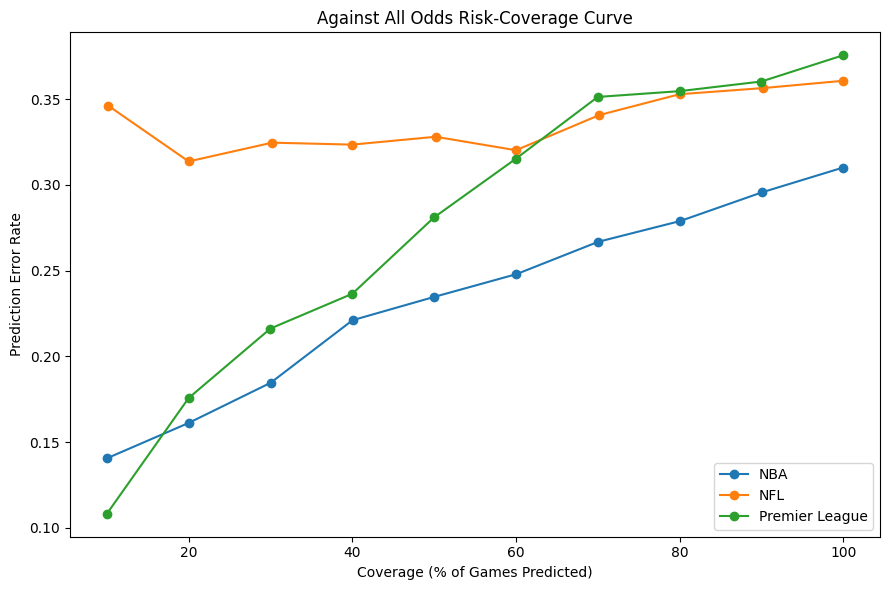

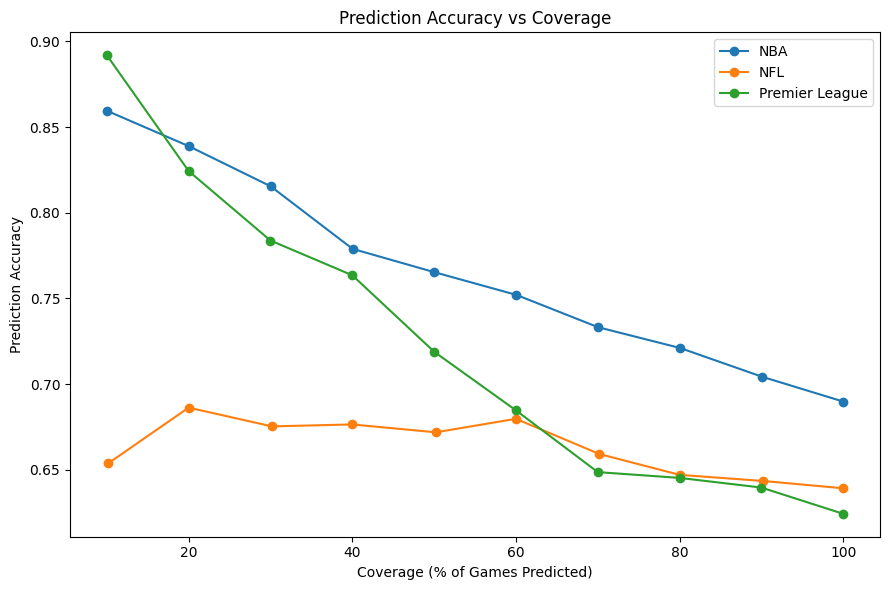

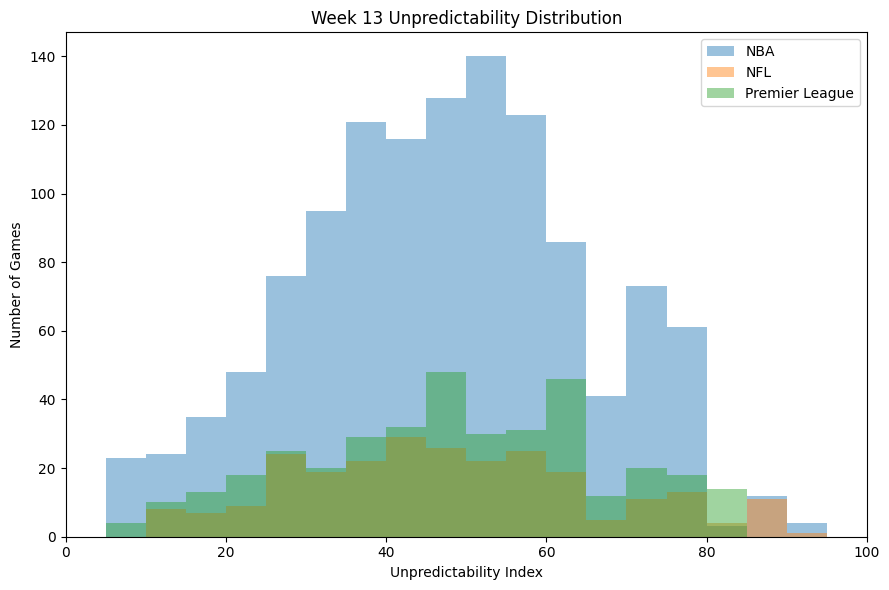

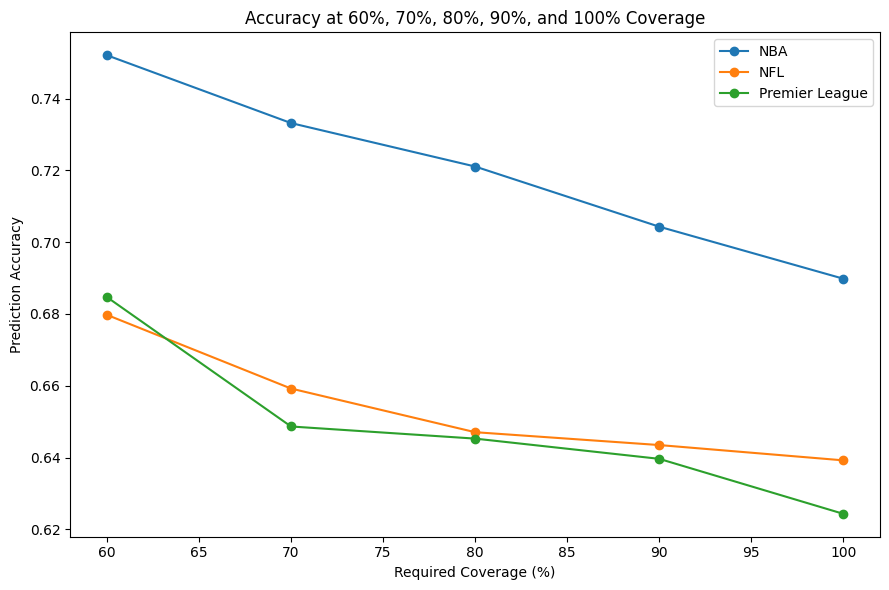


Week 13B quality checks:


,check,passed
0,three_sports_present,True
1,required_coverages_present,True
2,fifteen_required_rows,True
3,risk_curve_complete,True
4,accuracy_valid,True
5,error_rate_valid,True



✅ WEEK 13 COMPLETE
✅ Unpredictability Index
✅ Predict / Caution / Abstain
✅ 100 / 90 / 80 / 70 / 60% coverage experiment
✅ Risk-coverage curve
✅ Accuracy-vs-coverage chart
✅ GitHub upload ZIP: /content/Against_All_Odds_Week13_GitHub_Upload.zip

Next: Week 14 — Cross-Sport Analysis and Final Project


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import json, sys, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(x): print(x)

warnings.filterwarnings('ignore', category=FutureWarning)
PROJECT_TITLE = 'Against All Odds'
INDEX_INPUT = 'week13_unpredictability_index.csv'
REQUIRED_COVERAGES = [1.00,0.90,0.80,0.70,0.60]
CURVE_COVERAGES = [x/100 for x in range(10,101,10)]

print('='*78)
print('AGAINST ALL ODDS — WEEK 13B: ABSTENTION ANALYSIS')
print('='*78)


def running_in_colab(): return 'google.colab' in sys.modules


def choose_project_root():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd if cwd.name.lower().replace('_','-') in {'againstallodds','against-all-odds'} else None,
        Path('/content/againstallodds'), Path('/content/Against-All-Odds'),
        Path('/content/drive/MyDrive/againstallodds'), Path('/content/drive/MyDrive/Against-All-Odds')]
    for c in candidates:
        if c is not None and c.exists(): return c
    return Path('/content/againstallodds') if running_in_colab() else cwd/'againstallodds'


PROJECT_ROOT = choose_project_root()
RESULTS_DIR = PROJECT_ROOT/'results'
FIGURES_DIR = PROJECT_ROOT/'figures'/'week13'
DOCS_DIR = PROJECT_ROOT/'docs'
for p in [RESULTS_DIR, FIGURES_DIR, DOCS_DIR]: p.mkdir(parents=True, exist_ok=True)


def search_locations():
    locs = [PROJECT_ROOT, RESULTS_DIR, Path('/content'), Path('/content/week13_inputs'), Path.cwd().resolve()]
    for extra in [Path('/content/drive/MyDrive/againstallodds'), Path('/content/drive/MyDrive/Against-All-Odds')]:
        if extra.exists(): locs.append(extra)
    return list(dict.fromkeys(p for p in locs if p.exists()))


def find_file(name):
    for root in search_locations():
        p = root/name
        if p.exists(): return p
    for root in search_locations():
        try: hits = list(root.rglob(name))
        except (PermissionError,OSError): hits = []
        if hits: return hits[0]
    return None


index_path = find_file(INDEX_INPUT)
if index_path is None and running_in_colab():
    print('Upload week13_unpredictability_index.csv if Notebook 15 was run in another runtime.')
    from google.colab import files
    uploaded = files.upload(); udir = Path('/content/week13_inputs'); udir.mkdir(parents=True, exist_ok=True)
    for name, blob in uploaded.items():
        dst = udir/Path(name).name; dst.write_bytes(blob)
        if zipfile.is_zipfile(dst):
            with zipfile.ZipFile(dst,'r') as z: z.extractall(udir)
    index_path = find_file(INDEX_INPUT)
if index_path is None: raise FileNotFoundError('week13_unpredictability_index.csv not found. Run Notebook 15 first.')
print('Index input:', index_path)

df = pd.read_csv(index_path, dtype={'game_id':'string'})
required = ['sport','game_id','HOME_WIN','WINNER_PREDICTION','WINNER_PREDICTION_CORRECT','UNPREDICTABILITY_INDEX','RELIABILITY_CATEGORY','ERROR_RISK_PROBABILITY','FRAGILITY_SCORE']
missing = [c for c in required if c not in df.columns]
if missing: raise ValueError(f'Week 13 index file missing columns: {missing}')
df['sport'] = df['sport'].astype('string').str.strip(); df['game_id'] = df['game_id'].astype('string')
for c in ['HOME_WIN','WINNER_PREDICTION','WINNER_PREDICTION_CORRECT','UNPREDICTABILITY_INDEX','ERROR_RISK_PROBABILITY','FRAGILITY_SCORE']:
    df[c] = pd.to_numeric(df[c], errors='coerce')
if not df['UNPREDICTABILITY_INDEX'].between(0,100).all(): raise ValueError('UNPREDICTABILITY_INDEX must be 0–100.')

# Rank lowest-uncertainty games first within each sport
ranked_frames = []
for sport in ['NBA','NFL','Premier League']:
    s = df[df['sport'].eq(sport)].copy().sort_values(['UNPREDICTABILITY_INDEX','game_id'], kind='stable').reset_index(drop=True)
    s['UNCERTAINTY_RANK'] = np.arange(1,len(s)+1)
    s['COVERAGE_PERCENTILE'] = s['UNCERTAINTY_RANK']/len(s)
    ranked_frames.append(s)
ranked = pd.concat(ranked_frames, ignore_index=True)
RANKED_PATH = RESULTS_DIR/'week13_ranked_predictions_for_abstention.csv'; ranked.to_csv(RANKED_PATH,index=False)


def evaluate_coverage(sport_df, coverage):
    x = sport_df.sort_values(['UNPREDICTABILITY_INDEX','game_id'], kind='stable').reset_index(drop=True)
    total = len(x); keep_n = max(1,min(total,int(np.ceil(total*coverage))))
    kept = x.iloc[:keep_n]; dropped = x.iloc[keep_n:]
    acc = float(kept['WINNER_PREDICTION_CORRECT'].mean())
    return {
        'requested_coverage': coverage,
        'requested_coverage_percent': 100*coverage,
        'total_games': int(total),
        'games_predicted': int(keep_n),
        'games_abstained': int(total-keep_n),
        'realized_coverage': keep_n/total,
        'realized_coverage_percent': 100*keep_n/total,
        'abstention_rate': 1-keep_n/total,
        'prediction_accuracy': acc,
        'prediction_error_rate': 1-acc,
        'mean_retained_unpredictability': float(kept['UNPREDICTABILITY_INDEX'].mean()),
        'max_retained_unpredictability': float(kept['UNPREDICTABILITY_INDEX'].max()),
        'mean_abstained_unpredictability': float(dropped['UNPREDICTABILITY_INDEX'].mean()) if len(dropped) else np.nan,
        'mean_retained_error_risk': float(kept['ERROR_RISK_PROBABILITY'].mean()),
        'mean_retained_fragility': float(kept['FRAGILITY_SCORE'].mean()),
    }

# Required 100/90/80/70/60 experiment
rows = []
for sport in ['NBA','NFL','Premier League']:
    s = ranked[ranked['sport'].eq(sport)]
    for cov in REQUIRED_COVERAGES:
        r = evaluate_coverage(s,cov); r['sport'] = sport; rows.append(r)
coverage = pd.DataFrame(rows)
coverage['accuracy_improvement_vs_100pct'] = np.nan
for sport in ['NBA','NFL','Premier League']:
    base = float(coverage.loc[coverage['sport'].eq(sport)&coverage['requested_coverage'].eq(1.0),'prediction_accuracy'].iloc[0])
    mask = coverage['sport'].eq(sport)
    coverage.loc[mask,'accuracy_improvement_vs_100pct'] = coverage.loc[mask,'prediction_accuracy']-base
COVERAGE_PATH = RESULTS_DIR/'week13_abstention_coverage_results.csv'; coverage.to_csv(COVERAGE_PATH,index=False)
print('\nRequired 100/90/80/70/60 coverage experiment:')
display(coverage[['sport','requested_coverage_percent','games_predicted','games_abstained','prediction_accuracy','prediction_error_rate','accuracy_improvement_vs_100pct']])

# Full curve
curve_rows = []
for sport in ['NBA','NFL','Premier League']:
    s = ranked[ranked['sport'].eq(sport)]
    for cov in CURVE_COVERAGES:
        r = evaluate_coverage(s,cov); r['sport'] = sport; curve_rows.append(r)
risk_curve = pd.DataFrame(curve_rows)
RISK_PATH = RESULTS_DIR/'week13_risk_coverage_curve.csv'; risk_curve.to_csv(RISK_PATH,index=False)

# Predict/Caution/Abstain results
cat = ranked.groupby(['sport','RELIABILITY_CATEGORY'], observed=False).agg(
    games=('game_id','size'),
    prediction_accuracy=('WINNER_PREDICTION_CORRECT','mean'),
    mean_unpredictability_index=('UNPREDICTABILITY_INDEX','mean'),
    mean_error_risk_probability=('ERROR_RISK_PROBABILITY','mean'),
    mean_fragility_score=('FRAGILITY_SCORE','mean'),
).reset_index()
cat['prediction_error_rate'] = 1-cat['prediction_accuracy']
CATEGORY_PATH = RESULTS_DIR/'week13_predict_caution_abstain_results.csv'; cat.to_csv(CATEGORY_PATH,index=False)
print('\nPredict / Caution / Abstain performance:'); display(cat)

# Figures
fig, ax = plt.subplots(figsize=(9,6))
for sport in ['NBA','NFL','Premier League']:
    s = risk_curve[risk_curve['sport'].eq(sport)].sort_values('realized_coverage_percent')
    ax.plot(s['realized_coverage_percent'], s['prediction_error_rate'], marker='o', label=sport)
ax.set(xlabel='Coverage (% of Games Predicted)', ylabel='Prediction Error Rate', title='Against All Odds Risk-Coverage Curve')
ax.legend(); fig.tight_layout(); RISK_FIG = FIGURES_DIR/'week13_risk_coverage_curve.png'; fig.savefig(RISK_FIG,dpi=160,bbox_inches='tight'); plt.show(); plt.close(fig)

fig, ax = plt.subplots(figsize=(9,6))
for sport in ['NBA','NFL','Premier League']:
    s = risk_curve[risk_curve['sport'].eq(sport)].sort_values('realized_coverage_percent')
    ax.plot(s['realized_coverage_percent'], s['prediction_accuracy'], marker='o', label=sport)
ax.set(xlabel='Coverage (% of Games Predicted)', ylabel='Prediction Accuracy', title='Prediction Accuracy vs Coverage')
ax.legend(); fig.tight_layout(); ACC_FIG = FIGURES_DIR/'week13_accuracy_vs_coverage.png'; fig.savefig(ACC_FIG,dpi=160,bbox_inches='tight'); plt.show(); plt.close(fig)

fig, ax = plt.subplots(figsize=(9,6))
for sport in ['NBA','NFL','Premier League']:
    vals = ranked.loc[ranked['sport'].eq(sport),'UNPREDICTABILITY_INDEX']
    ax.hist(vals,bins=np.arange(0,105,5),alpha=.45,label=sport)
ax.set(xlim=(0,100), xlabel='Unpredictability Index', ylabel='Number of Games', title='Week 13 Unpredictability Distribution')
ax.legend(); fig.tight_layout(); DIST_FIG = FIGURES_DIR/'week13_unpredictability_distribution_all_sports.png'; fig.savefig(DIST_FIG,dpi=160,bbox_inches='tight'); plt.show(); plt.close(fig)

fig, ax = plt.subplots(figsize=(9,6))
for sport in ['NBA','NFL','Premier League']:
    s = coverage[coverage['sport'].eq(sport)].sort_values('requested_coverage_percent')
    ax.plot(s['requested_coverage_percent'], s['prediction_accuracy'], marker='o', label=sport)
ax.set(xlabel='Required Coverage (%)', ylabel='Prediction Accuracy', title='Accuracy at 60%, 70%, 80%, 90%, and 100% Coverage')
ax.legend(); fig.tight_layout(); REQ_FIG = FIGURES_DIR/'week13_required_coverage_accuracy.png'; fig.savefig(REQ_FIG,dpi=160,bbox_inches='tight'); plt.show(); plt.close(fig)

# Benefit summary
benefit_rows = []
for cov in REQUIRED_COVERAGES:
    s = coverage[coverage['requested_coverage'].eq(cov)].sort_values('accuracy_improvement_vs_100pct',ascending=False)
    top = s.iloc[0]
    benefit_rows.append({'requested_coverage_percent':100*cov,'sport_with_largest_accuracy_gain':top['sport'],'largest_accuracy_gain':float(top['accuracy_improvement_vs_100pct'])})
benefit = pd.DataFrame(benefit_rows)
BENEFIT_PATH = RESULTS_DIR/'week13_abstention_benefit_summary.csv'; benefit.to_csv(BENEFIT_PATH,index=False)

methodology = {
    'project': PROJECT_TITLE,
    'week': 13,
    'experiment': 'Abstain from highest-Unpredictability games first',
    'required_coverages': ['100%','90%','80%','70%','60%'],
    'ranking_rule': 'Within each sport, sort TEST games from lowest to highest Unpredictability Index.',
    'coverage_definition': 'Share of games for which a winner prediction is retained.',
    'risk_definition': 'Prediction error rate among retained games.',
    'evaluation_split': 'TEST',
}
METH_PATH = RESULTS_DIR/'week13_abstention_methodology.json'; METH_PATH.write_text(json.dumps(methodology,indent=2),encoding='utf-8')

result_lines = []
for sport in ['NBA','NFL','Premier League']:
    s = coverage[coverage['sport'].eq(sport)]
    a100 = float(s.loc[s['requested_coverage'].eq(1.0),'prediction_accuracy'].iloc[0])
    a60 = float(s.loc[s['requested_coverage'].eq(.60),'prediction_accuracy'].iloc[0])
    result_lines.append(f'- {sport}: accuracy changed from {a100:.1%} at 100% coverage to {a60:.1%} at 60% coverage.')

doc = f'''# Against All Odds — Week 13B Abstention Analysis

Generated: {datetime.now(timezone.utc).isoformat(timespec='seconds')}

The abstention experiment tests whether prediction accuracy improves when the system refuses to predict the games with the highest Unpredictability Index.

Games are ranked from lowest to highest uncertainty. Accuracy is then measured while retaining 100%, 90%, 80%, 70%, and 60% of games.

{chr(10).join(result_lines)}

Coverage is the share of games still receiving a prediction. Risk is the prediction error rate among retained games. If the reliability system works well, removing the highest-risk games should generally reduce error and improve accuracy.
'''
DOC_PATH = DOCS_DIR/'week13_abstention_analysis.md'; DOC_PATH.write_text(doc,encoding='utf-8')
README_PATH = DOCS_DIR/'week13_README_addition.md'; README_PATH.write_text('''## Week 13 — Unpredictability Index and Abstention\n\nCombined winner prediction, calibrated probability, Fragility Score, error-risk probability, and model disagreement into the Against All Odds Unpredictability Index. Games were classified as Predict, Caution, or Abstain. The main experiment compared accuracy at 100%, 90%, 80%, 70%, and 60% coverage by removing the highest-Unpredictability games first. Risk-coverage, unpredictability-distribution, and accuracy-vs-coverage figures were created for the NBA, NFL, and Premier League.\n''',encoding='utf-8')

checks = {
    'three_sports_present': set(ranked['sport'].unique()) == {'NBA','NFL','Premier League'},
    'required_coverages_present': set(np.round(coverage['requested_coverage'].unique(),2)) == set(REQUIRED_COVERAGES),
    'fifteen_required_rows': len(coverage) == 15,
    'risk_curve_complete': len(risk_curve) == 3*len(CURVE_COVERAGES),
    'accuracy_valid': coverage['prediction_accuracy'].between(0,1).all() and risk_curve['prediction_accuracy'].between(0,1).all(),
    'error_rate_valid': coverage['prediction_error_rate'].between(0,1).all() and risk_curve['prediction_error_rate'].between(0,1).all(),
}
q = pd.DataFrame([{'check':k,'passed':bool(v)} for k,v in checks.items()]); QUALITY_PATH = RESULTS_DIR/'week13_abstention_quality_report.csv'; q.to_csv(QUALITY_PATH,index=False)
print('\nWeek 13B quality checks:'); display(q)
if not q['passed'].all(): raise RuntimeError('Week 13B quality checks failed.')

# Runtime GitHub package
runtime_files = list(RESULTS_DIR.glob('week13_*')) + list(FIGURES_DIR.glob('week13_*.png'))
for p in [DOCS_DIR/'week13_unpredictability_index.md',DOC_PATH,README_PATH]:
    if p.exists(): runtime_files.append(p)
runtime_files = list(dict.fromkeys(p for p in runtime_files if p.exists()))
push_list = '''AGAINST ALL ODDS — WEEK 13 GITHUB PUSH LIST\n\nnotebooks/\n  15_unpredictability_index.ipynb\n  16_abstention_analysis.ipynb\n\ndocs/\n  week13_unpredictability_index.md\n  week13_abstention_analysis.md\n  week13_README_addition.md\n\nresults/\n  week13_unpredictability_index.csv\n  week13_unpredictability_summary_by_sport.csv\n  week13_reliability_category_summary.csv\n  week13_unpredictability_component_summary.csv\n  week13_unpredictability_methodology.json\n  week13_unpredictability_quality_report.csv\n  week13_ranked_predictions_for_abstention.csv\n  week13_abstention_coverage_results.csv\n  week13_risk_coverage_curve.csv\n  week13_predict_caution_abstain_results.csv\n  week13_abstention_benefit_summary.csv\n  week13_abstention_methodology.json\n  week13_abstention_quality_report.csv\n\nfigures/week13/\n  week13_nba_unpredictability_distribution.png\n  week13_nfl_unpredictability_distribution.png\n  week13_premier_league_unpredictability_distribution.png\n  week13_mean_unpredictability_by_sport.png\n  week13_reliability_categories_by_sport.png\n  week13_risk_coverage_curve.png\n  week13_accuracy_vs_coverage.png\n  week13_unpredictability_distribution_all_sports.png\n  week13_required_coverage_accuracy.png\n\nAlso update README.md using docs/week13_README_addition.md\n'''
CHECKLIST = PROJECT_ROOT/'WEEK13_GITHUB_PUSH_LIST.txt'; CHECKLIST.write_text(push_list,encoding='utf-8')
WEEK13_ZIP = Path('/content/Against_All_Odds_Week13_GitHub_Upload.zip') if running_in_colab() else PROJECT_ROOT/'Against_All_Odds_Week13_GitHub_Upload.zip'
if WEEK13_ZIP.exists(): WEEK13_ZIP.unlink()
with zipfile.ZipFile(WEEK13_ZIP,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in runtime_files: z.write(p,arcname=str(p.relative_to(PROJECT_ROOT)))
    z.write(CHECKLIST,arcname='WEEK13_GITHUB_PUSH_LIST.txt')

print('\n✅ WEEK 13 COMPLETE')
print('✅ Unpredictability Index')
print('✅ Predict / Caution / Abstain')
print('✅ 100 / 90 / 80 / 70 / 60% coverage experiment')
print('✅ Risk-coverage curve')
print('✅ Accuracy-vs-coverage chart')
print('✅ GitHub upload ZIP:', WEEK13_ZIP)
print('\nNext: Week 14 — Cross-Sport Analysis and Final Project')

if running_in_colab():
    try:
        from google.colab import files
        files.download(str(WEEK13_ZIP))
    except Exception as e:
        print('ZIP saved at:', WEEK13_ZIP)
        print('Download error:', e)
